# Mint Technologies
## Milestone 04: Deeper Analysis — RFM Customer Segmentation

### 1. Project Overview

This project applies RFM (Recency, Frequency, and Monetary) analysis to retail sales data to understand customer purchasing behavior and identify valuable customer segments.

### 2. Objectives

- Calculate Recency, Frequency, and Monetary values for each customer.
- Assign RFM scores to customers.
- Segment customers based on purchasing behavior.
- Visualize customer segments and interpret business insights.

# Import libraries and load your dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
sns.set_theme(style="whitegrid")

file_path = Path(
    r"C:\Users\bhumi\Downloads\Mint Technologies\Retail_Sales_Cleaning\data\cleaned\cleaned_dataset.csv"
)


In [3]:
df = pd.read_csv(file_path)

In [4]:
df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)

In [5]:
df["sales"] = pd.to_numeric(
    df["sales"], errors="coerce"
)

In [6]:
df = df.dropna(
    subset=["customer_id", "order_id", "order_date", "sales"]
)


In [7]:
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (9800, 18)


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub-category,product_name,sales
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


# Calculate RFM metrics(Recency, Frequency, and Monetary.)

In [8]:
# Reference date: one day after the latest order date
reference_date = df["order_date"].max() + pd.Timedelta(days=1)

rfm = df.groupby("customer_id").agg(
    last_purchase=("order_date", "max"),
    frequency=("order_id", "nunique"),
    monetary=("sales", "sum")
)

rfm["recency"] = (
    reference_date - rfm["last_purchase"]
).dt.days

rfm = rfm[
    ["recency", "frequency", "monetary"]
].reset_index()

rfm["monetary"] = rfm["monetary"].round(2)

print("RFM metrics calculated successfully!")
display(rfm.head(10))

RFM metrics calculated successfully!


,customer_id,recency,frequency,monetary
0,AA-10315,185,5,5563.56
1,AA-10375,20,9,1056.39
2,AA-10480,260,4,1790.51
3,AA-10645,56,6,5086.93
4,AB-10015,416,3,886.16
5,AB-10060,55,8,7755.62
6,AB-10105,42,10,14473.57
7,AB-10150,42,5,966.71
8,AB-10165,26,8,1113.84
9,AB-10255,167,9,914.53


In [ ]:
# recency: Number of days since the customer's latest purchase. Lower is better.
frequency: Number of distinct orders placed by the customer.
monetary: Total recorded sales value for that customer.

###  Assign RFM Scores.

In [9]:
# Rank first to handle repeated values safely when creating five groups
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

rfm["RFM_total"] = (
    rfm["R_score"]
    + rfm["F_score"]
    + rfm["M_score"]
)

display(rfm.head(10))

,customer_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_total
0,AA-10315,185,5,5563.56,2,2,5,225,9
1,AA-10375,20,9,1056.39,5,5,2,552,12
2,AA-10480,260,4,1790.51,1,1,3,113,5
3,AA-10645,56,6,5086.93,3,3,5,335,11
4,AB-10015,416,3,886.16,1,1,1,111,3
5,AB-10060,55,8,7755.62,3,4,5,345,12
6,AB-10105,42,10,14473.57,4,5,5,455,14
7,AB-10150,42,5,966.71,4,2,2,422,8
8,AB-10165,26,8,1113.84,5,4,2,542,11
9,AB-10255,167,9,914.53,2,5,1,251,8


# Create customer segments

In [10]:
def assign_segment(row):
    if row["RFM_total"] >= 13 and row["R_score"] >= 4:
        return "Champions"
    elif row["F_score"] >= 4 and row["R_score"] >= 3:
        return "Loyal Customers"
    elif row["R_score"] >= 4 and row["F_score"] >= 2:
        return "Potential Loyalists"
    elif row["R_score"] <= 2 and row["F_score"] >= 3:
        return "At Risk"
    elif row["R_score"] <= 2 and row["F_score"] <= 2:
        return "Hibernating"
    else:
        return "Other Customers"

rfm["segment"] = rfm.apply(assign_segment, axis=1)

print("Customer segmentation completed!")
display(rfm.head(10))

Customer segmentation completed!


,customer_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_total,segment
0,AA-10315,185,5,5563.56,2,2,5,225,9,Hibernating
1,AA-10375,20,9,1056.39,5,5,2,552,12,Loyal Customers
2,AA-10480,260,4,1790.51,1,1,3,113,5,Hibernating
3,AA-10645,56,6,5086.93,3,3,5,335,11,Other Customers
4,AB-10015,416,3,886.16,1,1,1,111,3,Hibernating
5,AB-10060,55,8,7755.62,3,4,5,345,12,Loyal Customers
6,AB-10105,42,10,14473.57,4,5,5,455,14,Champions
7,AB-10150,42,5,966.71,4,2,2,422,8,Potential Loyalists
8,AB-10165,26,8,1113.84,5,4,2,542,11,Loyal Customers
9,AB-10255,167,9,914.53,2,5,1,251,8,At Risk


# Visualize customer segments

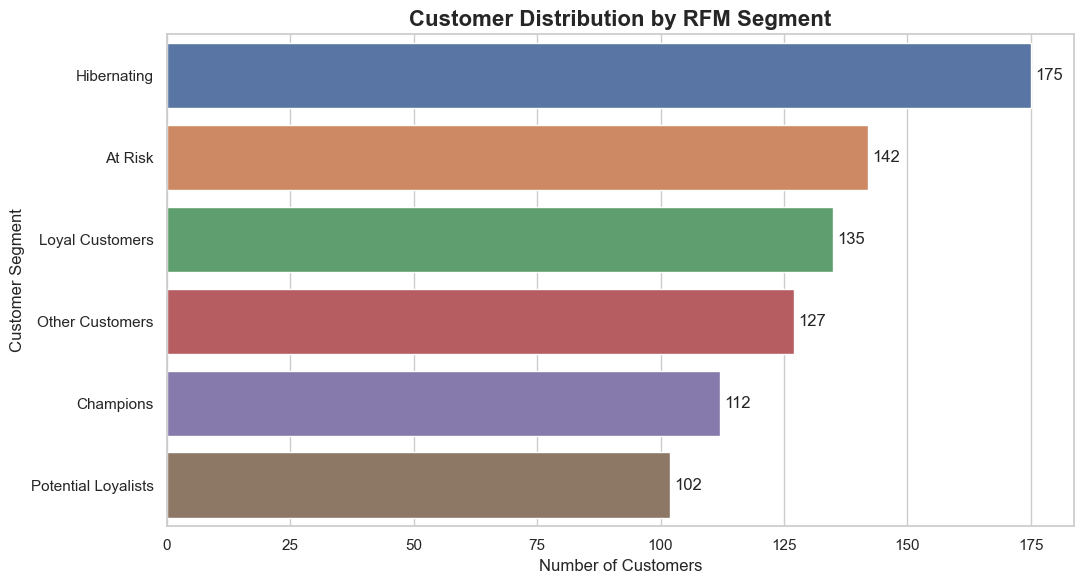

In [11]:
plt.figure(figsize=(11, 6))

ax = sns.countplot(
    data=rfm,
    y="segment",
    order=rfm["segment"].value_counts().index
)

ax.set_title(
    "Customer Distribution by RFM Segment",
    fontsize=16,
    weight="bold"
)
ax.set_xlabel("Number of Customers")
ax.set_ylabel("Customer Segment")

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

# **Business Takeaway**

The chart shows how customers are distributed across RFM segments. The size of each segment can help the business prioritize customer retention, loyalty initiatives, and re-engagement campaigns. Actual priorities should be based on the segment counts and sales values observed in the results.

# Compare customer frequency and monetary value

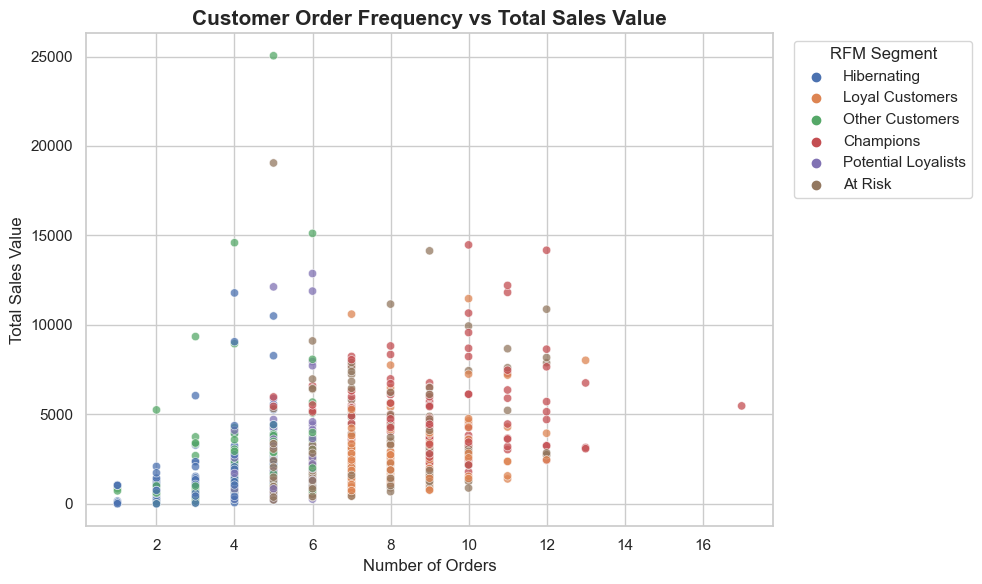

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="frequency",
    y="monetary",
    hue="segment",
    alpha=0.75
)

plt.title(
    "Customer Order Frequency vs Total Sales Value",
    fontsize=15,
    weight="bold"
)
plt.xlabel("Number of Orders")
plt.ylabel("Total Sales Value")
plt.legend(title="RFM Segment", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

# **Business Takeaway**

This scatter plot compares customer order frequency with total recorded sales value. Customers with both high frequency and high monetary value may be suitable candidates for loyalty programs, while customers with low activity may need further investigation or targeted engagement.

# Save the RFM results

In [13]:
output_path = Path(
    r"C:\Users\bhumi\Downloads\Mint Technologies\Retail_Sales_Cleaning\rfm_customer_segments.csv"
)

rfm.to_csv(output_path, index=False)

print("RFM results saved successfully!")
print("File location:", output_path)

RFM results saved successfully!
File location: C:\Users\bhumi\Downloads\Mint Technologies\Retail_Sales_Cleaning\rfm_customer_segments.csv


##  Conclusion

In this milestone, I performed RFM (Recency, Frequency, and Monetary) analysis using Python and Pandas to explore retail customer purchasing behavior.

I calculated customer recency, order frequency, and total monetary value, assigned scores to these metrics, and grouped customers into rule-based segments. I also visualized customer segment distribution and the relationship between order frequency and monetary value.

This analysis provides a foundation for identifying valuable customers, supporting retention strategies, and exploring opportunities to re-engage less-active customers.

**Tools Used:** Python, Pandas, Matplotlib, Seaborn, Jupyter Notebook.